# Comparison between Distributed Acoustic Sensing and Fiber Bragg Grating

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import glob, os
import pandas as pd
from matplotlib.cm import ScalarMappable
import xarray as xr

## Creating needed folders

In [2]:
path_data_DAS = "../../../DAS_Caltech/"

In [3]:
path_plots = '../../plots/DAS_FBG_comparison/'

if not os.path.exists(path_plots):
    os.makedirs(path_plots)

## Comparison example

In [4]:
das_data = xr.open_dataset(path_data_DAS+'/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5')

In [5]:
ds = xr.open_dataset("../../../fbg_data_r/gunnvher_channel_5_fbg_cleaned_10s.nc")
mask = ds.Time.isin(das_data.time.values + int(1e9))
ds = ds.sel(Time=mask)
na = np.isfinite(ds.Wavelength_nm.sel(FBG=1))
ds = ds.sel(Time=na)
das_data = das_data.sel(time=na.values)

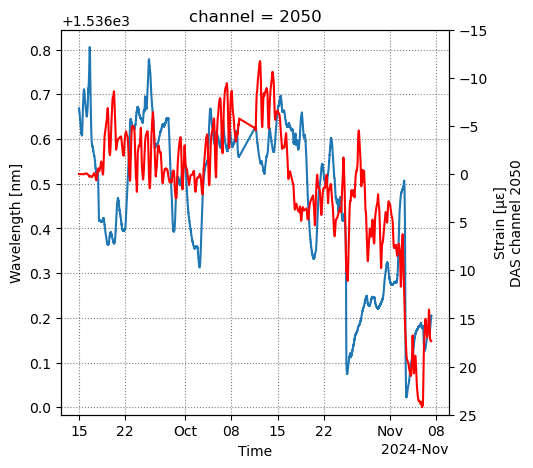

In [6]:
fig, ax = plt.subplots(figsize=(5,5))
ds.Wavelength_nm.sel(FBG=1).plot(ax=ax)
ax.set_ylabel('Wavelength [nm]')
axb = ax.twinx()
(das_data.strain.sel(channel=2050)).plot(ax=axb, c='r')
axb.set_ylim(25,-15)
axb.set_ylabel('Strain [µε]\nDAS channel 2050')
ax.grid(ls=':', c='k', alpha=0.5)
plt.show()

## Correlation coefficients

In [7]:
fbg_temps_files = glob.glob(r'../../../fbg_data_r/gunnvher_channel_*_fbg_cleaned_10s.nc')

channels = []
fbg = []
for i, f in enumerate(np.sort(fbg_temps_files)):
    #if 'channel_5' in f:
    #    continue
    ds_temp = xr.open_dataset(f)
    if i == 0:
        ds_all = ds_temp
    else:
        ds_all = xr.concat([ds_all, ds_temp], dim='FBG')
    channels += [int(f.split('_')[4])]*len(ds_temp.FBG)
    fbg += ds_temp.FBG.values.tolist()
    

In [8]:
def corr_coef_fbg_das(ds_all, das_data, plot = False, only_delay = False):
    delay = pd.Timestamp(das_data.time.values[0]).second%10
    if delay > 5 :
        delay = delay - 10
    
    if only_delay:
        return delay
    
    das_fbg_delay = int((10-delay)*1e9)
    fbg_ch = []
    Corr = np.full((len(ds_all.FBG),len(das_data.channel)), np.nan)
    for i in range(len(ds_all.FBG)):
        #print('FBG {}, Channel {}'.format(fbg[i], channels[i]))
        ds_ = ds_all.sel(FBG=i)
        fbg_ch.append([fbg[i], channels[i]])
        if np.isnan(ds_.Wavelength_nm.values).all():
            continue
        ds_ = ds_.sel(Time=ds_.Time.isin(das_data.time.values + das_fbg_delay))
        na = np.isfinite(ds_.Wavelength_nm)
        ds_ = ds_.sel(Time=na)
        das_data_ = das_data.sel(time=ds_.Time.values - das_fbg_delay)
        if plot :
            try :
                fig, ax = plt.subplots()
                ds_.Wavelength_nm.plot(ax=ax)
                axb = ax.twinx()
                das_data_.strain.sel(channel=channels[i]).plot(ax=axb, c='r')
                plt.title('FBG {}, Channel {}'.format(fbg[i], channels[i]))
                plt.show()
            except : print('Dont work')
        corrcoef = np.corrcoef(ds_.Wavelength_nm.values, das_data_.strain.values)
        Corr[i,:] = corrcoef[0,1:]

    mask = np.any(~np.isnan(Corr), axis=1)
    Corr = Corr[mask,:]
    fbg_ch = np.array(fbg_ch)[mask,:]

    return Corr, fbg_ch, delay

['../../../DAS_Caltech/1_das_strain_aug1_sep1_proc_ch_2000_2150.h5', '../../../DAS_Caltech/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5', '../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5']


/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:520: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: divide by zero encountered in divide
  ret = um.true_divide(
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: inva

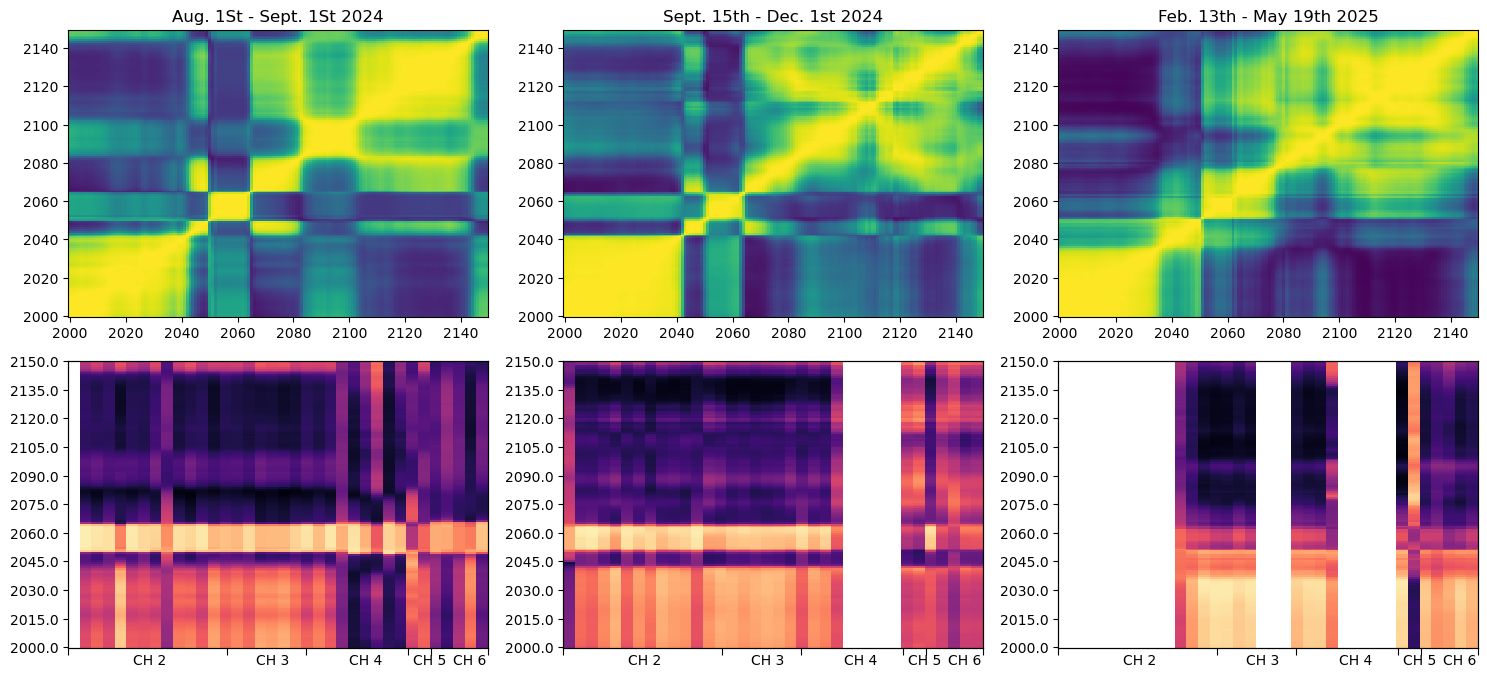

In [9]:
fig = plt.figure(figsize=(15,10))
das_files = glob.glob(path_data_DAS+'/*_das_strain_*.h5')
das_files.sort()
print(das_files)
title = ['Aug. 1St - Sept. 1St 2024','Sept. 15th - Dec. 1st 2024','Feb. 13th - May 19th 2025']

arrow = dict(arrowstyle = "|-|", ec='k')
bbox = dict(boxstyle='round', fc= 'lightgrey')

ch = [1,2,4,5,6]
nmax_fbg = [13,7,9,2,5]
combinations = []
for ch_ in ch :
    for n in range(nmax_fbg[ch.index(ch_)]):
        combinations.append('CH %i - FBG %i' %(ch_,n))
params_grid =(3,3)
for i, files in enumerate(das_files):
    
    das_data = xr.open_dataset(files)
    das_data['strain'] = das_data.strain - das_data.strain.mean(dim='channel')
    corrcoef_das = np.corrcoef(das_data.strain.values)
    ax = plt.subplot2grid(params_grid, (0,i))
    #ax[0,i].imshow(corrcoef_das, extent=(2000, 2000+das_data.strain.shape[0], 2000, 2000+das_data.strain.shape[0]), 
    #               origin='lower', aspect='auto', interpolation='none', cmap='viridis', vmin=-1, vmax=1)
    ax.pcolormesh(np.arange(2000, 2000+das_data.strain.shape[0]), np.arange(2000, 2000+das_data.strain.shape[0]), corrcoef_das,
                   shading='auto', cmap='viridis', vmin=-1, vmax=1)
    ax.set_title(title[i])

    
    Corr, fbg_ch, delay = corr_coef_fbg_das(ds_all, das_data, plot = False)
    all_corr_fbg_das = np.full((len(combinations), len(das_data.channel)), np.nan)
    for j in range(Corr.shape[0]):
        info = 'CH %i - FBG %i' %(fbg_ch[j,1], fbg_ch[j,0])
        index_ch = combinations.index(info)
        if i == 2 and index_ch == 0 :
            continue
        all_corr_fbg_das[index_ch,:] = Corr[j,:]
    axb = plt.subplot2grid(params_grid, (1,i))
    axb.imshow(all_corr_fbg_das.T, cmap='magma', aspect='auto', interpolation='none', origin='lower', vmin=-1, vmax=1)
    #ax[1,i].set_xticks([np.arange(len(fbg_ch)), ['CH %i - FBG %i' %(ch,fbg) for fbg, ch in fbg_ch], rotation=90])
    axb.set_xticks([],[])
    axb.set_yticks(np.linspace(0, Corr.shape[1], 11),np.linspace(0, Corr.shape[1], 11)+2000)
    
    #axb.annotate('', xy=(-0.5,0), xytext=(13.5,0),arrowprops = arrow, bbox=bbox)
    
    #axb.annotate('', xy=(13.5,0), xytext=(20.5,0),arrowprops = arrow, bbox=bbox)
    #axb.annotate('', xy=(19.5,0), xytext=(29.5,0),arrowprops = arrow, bbox=bbox)
    #axb.annotate('', xy=(28.5,0), xytext=(31,0),arrowprops = arrow, bbox=bbox)
    #axb.annotate('', xy=(30.5,0), xytext=(36,0),arrowprops = arrow, bbox=bbox)
    #shift = 2
    #ax[1,i].annotate('Channel 1', xy=(6.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 2', xy=(19.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 4', xy=(26.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 6', xy=(32.5-shift,2), bbox=bbox)

    #petit hack pour faire les ticks
    axb1 = axb.twiny()
    axb1.tick_params(axis='x', bottom=True, labelbottom=True, top=False, labeltop=False,length=5)
    axb1.set_xticks([-0.5, 13.5, 20.5,29.5,31.5,36.5], ['', '', '','', '', ''])
    axb.set_xticks([6.5, 17, 25, 30.5, 34], ['CH 2', 'CH 3', 'CH 4', 'CH 5', 'CH 6'])
    axb.tick_params(axis='x', length=0)
    #axb.set_title('Correlation Coefficient Matrix : FBG Temp vs DAS Strain')

#fig.colorbar(ax[0,0].collections[0], ax=ax[0,:], label='Correlation Coefficient', anchor=(0.5, 0.5))
#fig.colorbar(ax[1,0].images[0], ax=ax[1,:], label='Correlation Coefficient')

#ax[1,0].set_ylabel('DAS Channels'), ax[1,0].set_xlabel('FBG')
#ax[0,0].set_ylabel('DAS Channels'), ax[0,0].set_xlabel('DAS Channels')
plt.tight_layout()
plt.savefig(path_plots+'/correlation_coefficient_das_fbg.png', dpi=300, bbox_inches='tight')
plt.show()

## Import all data

### Importing DAS data

In [10]:
das_files = glob.glob('../../../DAS_Caltech/*das_strain_*.h5')
print('Files : ', das_files)
for i,f in enumerate(das_files) :
    delay = 10-pd.Timestamp(xr.open_dataset(f).time.values[0]).second%10
    print(delay)
    das_data = xr.open_dataset(f).sel(channel=slice(2055,2061))
    das_data['time'] = das_data.time.values.astype('datetime64[s]') + pd.Timedelta(seconds=delay)
    if i == 0 :
        das_temp = das_data
    else :
        das_temp = xr.concat([das_temp, das_data], dim='time')
#das_temp = xr.open_mfdataset(das_files).sel(channel=slice(2055,2061))

Files :  ['../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5', '../../../DAS_Caltech/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5', '../../../DAS_Caltech/1_das_strain_aug1_sep1_proc_ch_2000_2150.h5']
3
1
1


In [11]:
rng = np.arange(das_temp.time.values[0], das_temp.time.values[-1], np.timedelta64(10,'s'))
das_temp = das_temp.reindex(time=rng, method='nearest', fill_value=np.nan)

### Importing FBG and demeaning

In [12]:
fbg_temp = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_1_fbg_cleaned_10s.nc')

In [13]:
fbg_temp['Wavelength_nm'] = fbg_temp['Wavelength_nm'] - fbg_temp['Wavelength_nm'].mean(dim='Time')

In [14]:
#median_temp = np.nanmedian(fbg_temp.Wavelength_nm.values, axis=1)
#std_temp = np.nanstd(fbg_temp.Wavelength_nm.values, axis=1)
median_temp = fbg_temp.Wavelength_nm.median(dim='FBG')
std_temp = fbg_temp.Wavelength_nm.std(dim='FBG')

### Importing weather data

In [15]:
xl_weather = pd.read_excel('../../data/weather/Vedurgogn_VI_2026-03-23_rviti_31640.xlsx', sheet_name='Veðurathuganir', index_col='time')
xl_weather.index = pd.to_datetime(xl_weather.index)

## Plot

### Summary plot

['../../../DAS_Caltech//no_med_strain/1_das_strain_2024-07-31T23:59:59_2024-08-31T23:59:59.h5', '../../../DAS_Caltech//no_med_strain/2_das_strain_2024-09-14T23:59:59_2024-11-30T23:59:59.h5', '../../../DAS_Caltech//no_med_strain/3_das_strain_2025-02-13T09:52:17_2025-05-19T00:24:57.h5'] ['../../../DAS_Caltech/1_das_strain_aug1_sep1_proc_ch_2000_2150.h5', '../../../DAS_Caltech/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5', '../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5']


/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:520: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: divide by zero encountered in divide
  ret = um.true_divide(
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: inva

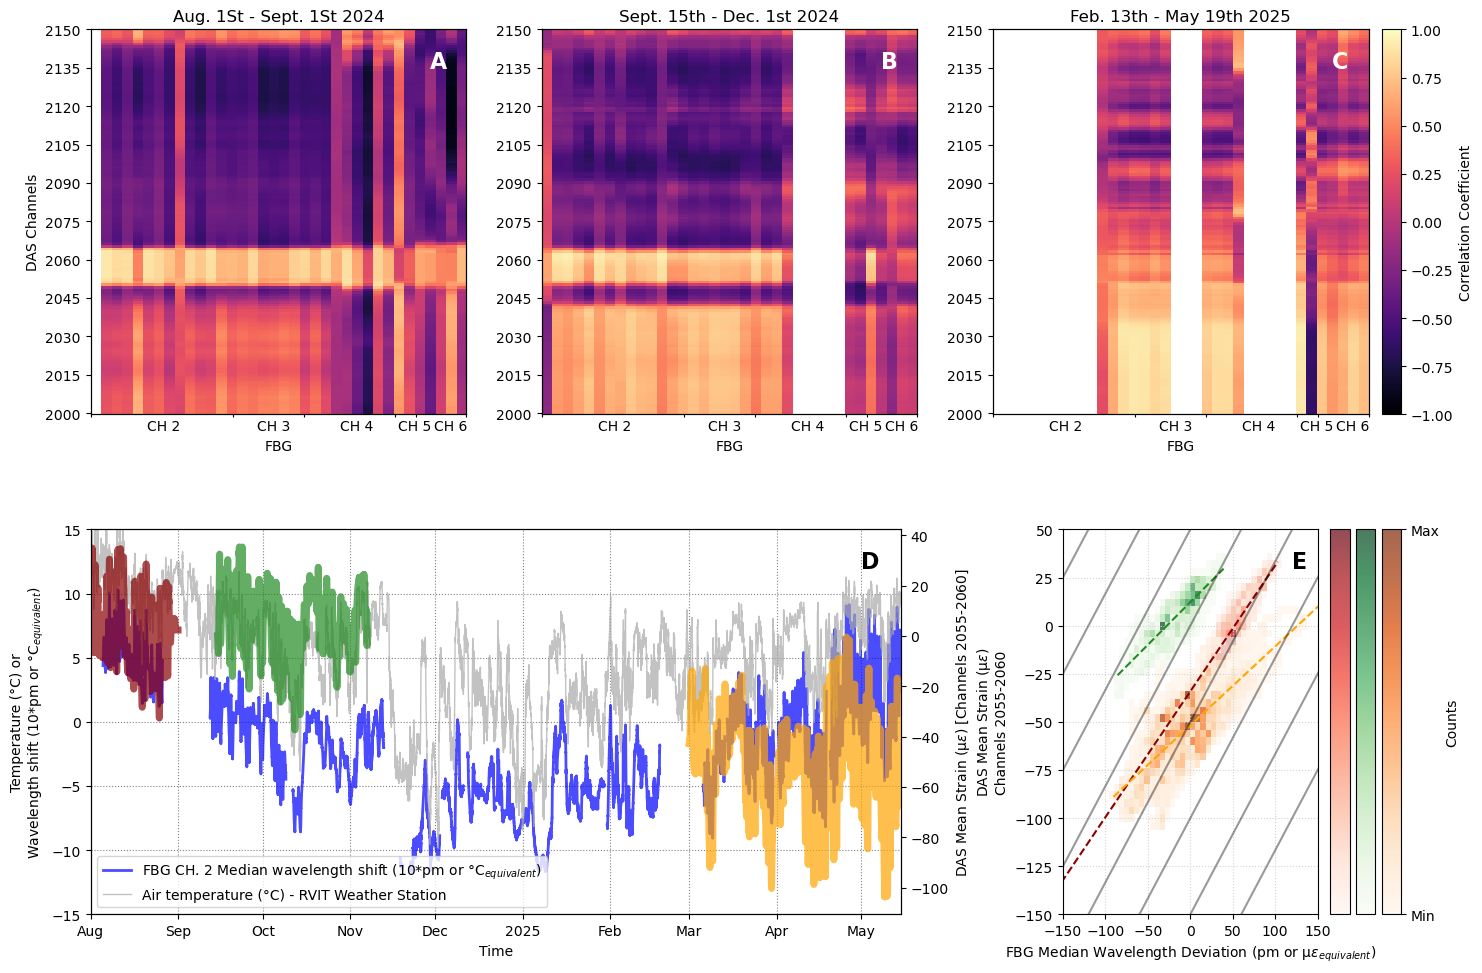

In [16]:
fig = plt.figure(figsize=(17,10))
(subfig_m, subfig_b) = fig.subfigures(nrows=2, ncols=1)
das_files = glob.glob(path_data_DAS+'/no_med_strain/*_das_strain_*.h5')
das_files_filtered = glob.glob(path_data_DAS+'/*_das_strain_*.h5')
das_files.sort()
das_files_filtered.sort()
print(das_files, das_files_filtered)
title = ['Aug. 1St - Sept. 1St 2024','Sept. 15th - Dec. 1st 2024','Feb. 13th - May 19th 2025']

arrow = dict(arrowstyle = "|-|", ec='k')
bbox = dict(boxstyle='round', fc= 'lightgrey')

axbs = []
axs = []
ch = [1,2,4,5,6]
nmax_fbg = [13,7,9,2,5]
combinations = []
for ch_ in ch :
    for n in range(nmax_fbg[ch.index(ch_)]):
        combinations.append('CH %i - FBG %i' %(ch_,n))

colors, colormaps = ['darkred', 'forestgreen','orange'], ['Reds', 'Greens', 'Oranges']


params_grid =(1,9)

#ax = subfig_t.subplots(ncols=3)
axb = subfig_m.subplots(ncols=3)

axc = plt.subplot2grid(params_grid, (0,0), colspan=6, fig=subfig_b)
axd = plt.subplot2grid(params_grid, (0,7), colspan=2, fig=subfig_b)
axcb = axc.twinx()

#label_row_1 = ['A','B','C']
label_row_2 = ['A','B','C']
label_row_3 = ['D','E']

histplots = []

for i, files in enumerate(zip(das_files, das_files_filtered)):
    
    das_data = xr.open_dataset(files[1])
    das_data_unfiltered = xr.open_dataset(files[0])
    corrcoef_das = np.corrcoef(das_data.strain.values)


    
    #ax = plt.subplot2grid(params_grid, (0,i), fig=fig)
    
    #ax[0,i].imshow(corrcoef_das, extent=(2000, 2000+das_data.strain.shape[0], 2000, 2000+das_data.strain.shape[0]), 
    #               origin='lower', aspect='auto', interpolation='none', cmap='viridis', vmin=-1, vmax=1)
    #das_plot = ax[i].pcolormesh(np.arange(2000, 2000+das_data.strain.shape[0]), np.arange(2000, 2000+das_data.strain.shape[0]), corrcoef_das,
    #               shading='auto', cmap='viridis', vmin=-1, vmax=1)
    #ax[i].set_title(title[i])

    #ax[i].text(2135,2135, label_row_1[i], fontsize=16, fontweight='bold', c='k')
    
    Corr, fbg_ch, delay = corr_coef_fbg_das(ds_all, das_data, plot = False)
    all_corr_fbg_das = np.full((len(combinations), len(das_data.channel)), np.nan)
    
    for j in range(Corr.shape[0]):
        info = 'CH %i - FBG %i' %(fbg_ch[j,1], fbg_ch[j,0])
        index_ch = combinations.index(info)
        if i == 2 and index_ch == 0 :
            continue
        all_corr_fbg_das[index_ch,:] = Corr[j,:]

    #axb = plt.subplot2grid(params_grid, (1,i))
    corr_plot_fbg = axb[i].imshow(all_corr_fbg_das.T, cmap='magma', aspect='auto', interpolation='none', origin='lower', vmin=-1, vmax=1)
    #ax[1,i].set_xticks([np.arange(len(fbg_ch)), ['CH %i - FBG %i' %(ch,fbg) for fbg, ch in fbg_ch], rotation=90])
    axb[i].text(32,135, label_row_2[i], fontsize=16, fontweight='bold', c='white')
    axb[i].set_title(title[i])
    axb[i].set_xticks([],[])
    axb[i].set_yticks(np.linspace(0, Corr.shape[1], 11),(np.linspace(0, Corr.shape[1], 11)+2000).astype(int))
    
    #axb.annotate('', xy=(-0.5,0), xytext=(13.5,0),arrowprops = arrow, bbox=bbox)
    
    #axb.annotate('', xy=(13.5,0), xytext=(20.5,0),arrowprops = arrow, bbox=bbox)
    #axb.annotate('', xy=(20.5,0), xytext=(29.5,0),arrowprops = arrow, bbox=bbox)
    #axb.annotate('', xy=(29.5,0), xytext=(34.5,0),arrowprops = arrow, bbox=bbox)

    axb[i].set_xlabel('DAS Channels')
    axb[i].set_xlabel('FBG')
    #shift = 2
    #ax[1,i].annotate('Channel 1', xy=(6.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 2', xy=(19.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 4', xy=(26.5-shift,2), bbox=bbox)
    #ax[1,i].annotate('Channel 6', xy=(32.5-shift,2), bbox=bbox)
    axb1 = axb[i].twiny()
    axb1.tick_params(axis='x', bottom=True, labelbottom=True, top=False, labeltop=False,length=2)
    axb1.set_xticks([-0.5, 13.5, 20.5,29.5,31.5,36.5], ['', '', '','', '', ''])
    axb[i].set_xticks([6.5, 17, 25, 30.5, 34], ['CH 2', 'CH 3', 'CH 4', 'CH 5', 'CH 6'])
    axb[i].tick_params(axis='x', length=0)
    


    #das_temp = das_data.sel(channel=slice(2055,2060))
    das_temp = das_data_unfiltered.sel(channel=slice(2055,2060))
    if i == 2 :
        das_temp = das_temp.sel(time=slice('2025-03-01','2025-05-19'))
    #axc.set_ylabel('FBG CH. 2\nMedian wavelength shift (10*pm or °C$_{equivalent}$)', c='b')
    
    das_temp.strain.mean(dim='channel').plot(ax=axcb, c=colors[i], linewidth=5, alpha=0.7)
    


    times = np.isin(median_temp.dropna(dim='Time').Time.values,das_temp.time.values - int(delay*1e9))
    crop_time = median_temp.dropna(dim='Time').Time.values[times]
    crop_median_temp = median_temp.sel(Time=crop_time)

    times = np.isin(das_temp.time.values - int(delay*1e9), median_temp.dropna(dim='Time').Time.values)
    crop_das_temp = das_temp.sel(time=das_temp.time.values[times])

    m1,p1 = np.polyfit(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values, 1)
    axd.plot(np.linspace(np.min(crop_median_temp*1000), np.max(crop_median_temp*1000),10), 
            m1*np.linspace(np.min(crop_median_temp*1000), np.max(crop_median_temp*1000),10) + p1, c=colors[i], ls='--')
    #axd.text(0, -25, 'Y = {:.2f} X + ({:.2f})'.format(m1, p1),c=colors[i])
    histplot  = axd.hist2d(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values, 
               alpha=0.7, bins=50, range=[(-150, 150), (-150, 50)],cmin=1,cmap=colormaps[i])#, norm=PowerNorm(0.5))
    
    histplots.append(histplot[3])

#ax[0].set_ylabel('DAS Channels')
#ax[0].set_xlabel('DAS Channels')

axb[0].set_ylabel('DAS Channels')

axc.plot(fbg_temp.Time, median_temp*100, linewidth=2, c='b', alpha=0.7, label='FBG CH. 2 Median wavelength shift (10*pm or °C$_{equivalent}$)')
axc.grid(ls=':',c='grey')
axc.plot(xl_weather.index, xl_weather.t.values, c='darkgrey', linewidth=1, alpha=0.7, label='Air temperature (°C) - RVIT Weather Station')
#axc.set_ylabel('FBG CH. 2\nMedian wavelength shift (pm or µ$\epsilon _{equivalent}$)', c='b')    
#axc.set_ylabel('FBG CH. 2 Median wavelength shift (pm or µ$\epsilon _{equivalent}$)\nAir temperature (°C)\nRVITI Weather Station')
axc.set_ylabel('Temperature (°C) or\nWavelength shift (10*pm or °C$_{equivalent}$)')
axcb.set_ylabel('DAS Mean Strain (µ$\epsilon$) [Channels 2055-2060]')
#axcb.set_ylabel('Air temperature (°C)\nRVITI Weather Station', c='darkgrey')
axc.set_xlabel('Time')
axc.legend(loc='lower left')
axc.set_ylim(-15, 15)
for pp in range(-200, 201, 50):
    axd.plot(np.arange(-200, 201), np.arange(-200, 201)/1.2+pp, c='k', ls='-', label='Targeted relationship', alpha=0.4)
axc.set_xlim(np.datetime64("2024-08-01"), np.datetime64("2025-05-15"))
axd.set_ylabel('DAS Mean Strain (µ$\epsilon$)\nChannels 2055-2060')
axd.set_xlabel('FBG Median Wavelength Deviation (pm or µ$\epsilon _{equivalent}$)')
axd.grid(ls=':',c='lightgrey')
axc.text(np.datetime64('2025-05-01'),12, label_row_3[0], fontsize=16, fontweight='bold', c='k')
axd.text(120, 30, label_row_3[1], fontsize=16, fontweight='bold', c='k')

'''




#axd.colorbar(label='Counts', shrink=0.8)
axd.set_xlabel('FBG Median Wavelength Deviation (pm or µ$\epsilon _{equivalent}$)')
axd.set_ylabel('DAS Mean Strain (µ$\epsilon$)\nChannels 2055-2060')
axd.grid(ls=':',c='grey')
'''
#axb.set_title('Correlation Coefficient Matrix : FBG Temp vs DAS Strain')

#subfig_t.colorbar(ax[0].collections[0], ax=ax, label='Correlation Coefficient', anchor=(0.5, 0.5))
#fig.colorbar(ax[1,0].images[0], ax=ax[1,:], label='Correlation Coefficient')

#ax[1,0].set_ylabel('DAS Channels'), ax[1,0].set_xlabel('FBG')
#ax[0,0].set_ylabel('DAS Channels'), ax[0,0].set_xlabel('DAS Channels')
#axs.append(axc), axs.append(axcb), axs.append(axd)

#subfig_t.colorbar(das_plot, ax=ax, label='Correlation Coefficient', fraction=0.02, pad=0.01)
subfig_m.colorbar(mappable=corr_plot_fbg, ax=axb, label='Correlation Coefficient', fraction=0.02, pad=0.01)
cbar_b3 = subfig_b.colorbar(histplots[2], ax=[axc,axd], label='Counts', fraction=0.02, pad=0.0001)
cbar_b2 = subfig_b.colorbar(histplots[1], ax=[axc,axd], fraction=0.02, pad=0.0001)
cbar_b1 = subfig_b.colorbar(histplots[0], ax=[axc,axd], fraction=0.02, pad=0.01)

cbar_b1.set_ticks([]), cbar_b1.set_ticklabels([])
cbar_b2.set_ticks([]), cbar_b2.set_ticklabels([])
cbar_b3.set_ticks([0, np.max(histplots[2].get_array())]), cbar_b3.set_ticklabels(['Min', 'Max'])
#plt.tight_layout()
plt.savefig(path_plots+'/correlation_coefficient_das_fbg_smaller.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Linear regression DAS vs FBG

File :  ../../../DAS_Caltech//no_med_strain/1_das_strain_2024-07-31T23:59:59_2024-08-31T23:59:59.h5
Delay :  -1
DAS temp shape :  (267839,)
Matrix shape :  (177929,) (177929,)
File :  ../../../DAS_Caltech//no_med_strain/2_das_strain_2024-09-14T23:59:59_2024-11-30T23:59:59.h5
Delay :  -1
DAS temp shape :  (457920,)
Matrix shape :  (436694,) (436694,)
File :  ../../../DAS_Caltech//no_med_strain/3_das_strain_2025-02-13T09:52:17_2025-05-19T00:24:57.h5
Delay :  -3
DAS temp shape :  (682708,)
Matrix shape :  (598914,) (598914,)


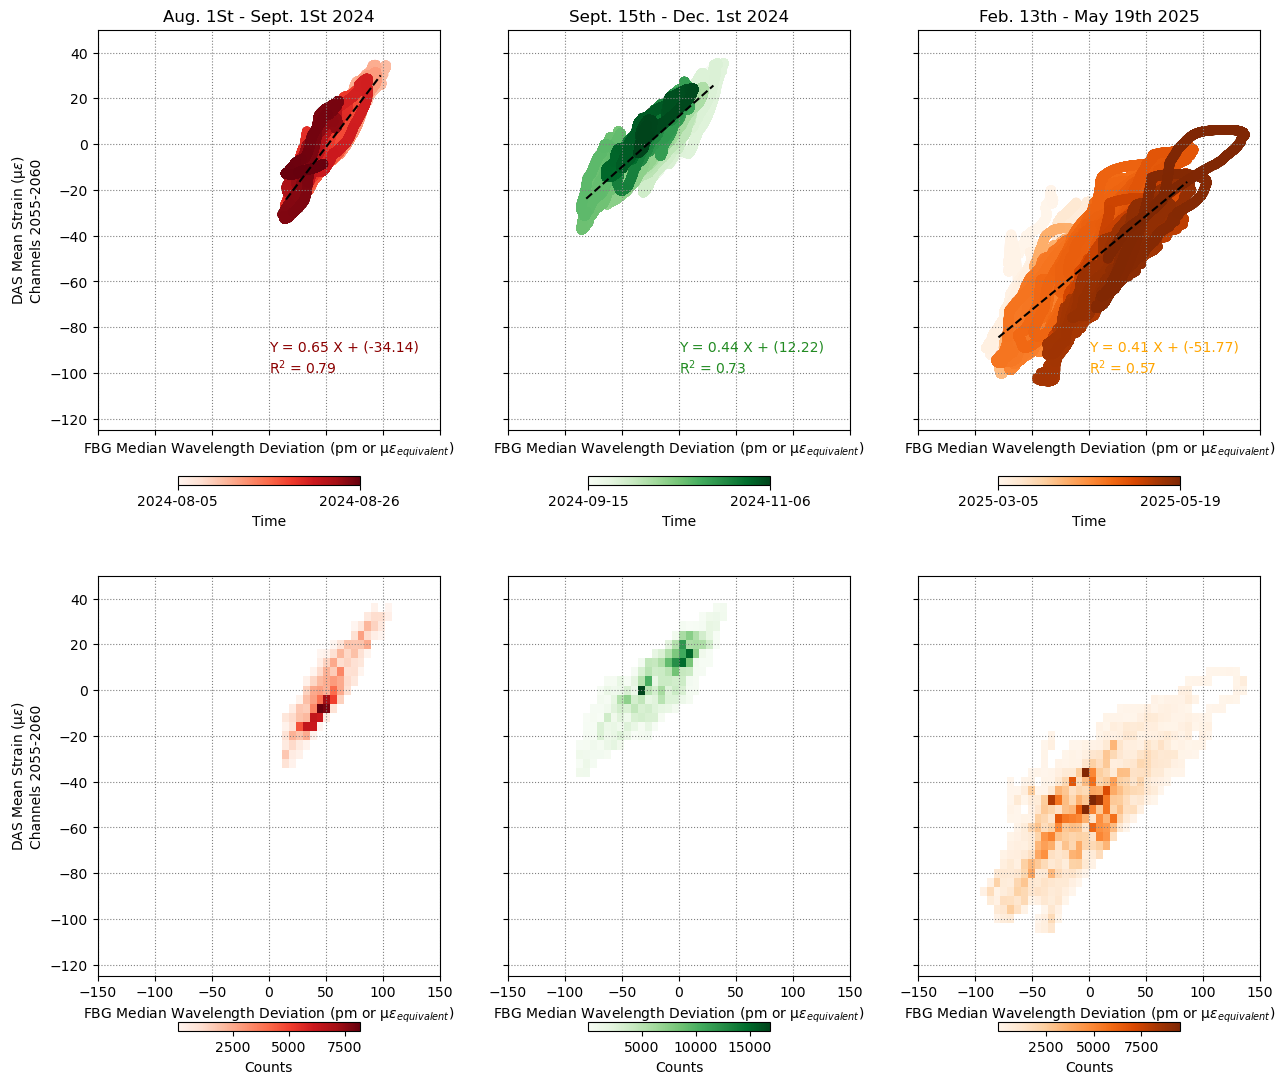

In [26]:
fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(15,13), sharex=True, sharey=True)
colors, colormaps = ['darkred', 'forestgreen','orange'], ['Reds', 'Greens', 'Oranges']
title = ['Aug. 1St - Sept. 1St 2024','Sept. 15th - Dec. 1st 2024','Feb. 13th - May 19th 2025']
das_files = glob.glob(path_data_DAS+'/no_med_strain/*_das_strain_*.h5')
das_files.sort()
for i, files in enumerate(das_files):
    
    das_data = xr.open_dataset(files)
    print('File : ', files)
    delay = corr_coef_fbg_das(ds_all, das_data, plot = False, only_delay=True)
    print('Delay : ', delay)
    das_temp = das_data.sel(channel=slice(2055,2060))
    if i == 2 : 
        das_temp = das_temp.sel(time=slice('2025-03-01','2025-05-19'))
    print('DAS temp shape : ', das_temp.strain.mean(dim='channel').values.shape)
    times = np.isin(median_temp.dropna(dim='Time').Time.values,das_temp.time.values - int(delay*1e9))
    crop_time = median_temp.dropna(dim='Time').Time.values[times]
    crop_median_temp = median_temp.sel(Time=crop_time)

    times = np.isin(das_temp.time.values - int(delay*1e9), median_temp.dropna(dim='Time').Time.values)
    crop_das_temp = das_temp.sel(time=das_temp.time.values[times])
    print('Matrix shape : ', crop_median_temp.shape, crop_das_temp.strain.mean(dim='channel').values.shape)
    axs[0][i].scatter(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values, alpha=0.7,
                   c=crop_das_temp.time.values.astype('datetime64[s]'), cmap=colormaps[i], label=title[i])
    m,p = np.polyfit(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values, 1)
    axs[0][i].plot(np.linspace(np.percentile(crop_median_temp*1000, 1), np.percentile(crop_median_temp*1000, 99),10), 
            m*np.linspace(np.percentile(crop_median_temp*1000, 1), np.percentile(crop_median_temp*1000, 99),10) + p, c='k', ls='--')
    axs[0][i].text(0, -100, 'Y = {:.2f} X + ({:.2f})\nR$^2$ = {:.2f}'.format(m, p, np.corrcoef(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values)[0,1]**2),c=colors[i])
    axs[0][i].set_xlabel('FBG Median Wavelength Deviation (pm or µ$\epsilon _{equivalent}$)')
    axs[0][i].set_title(title[i])
    axs[0][i].grid(ls=':',c='grey')
    #axs[i].legend()
    cbar = fig.colorbar(ScalarMappable(cmap=colormaps[i], norm=mcolors.Normalize(vmin=0, vmax=1)), 
                        ax=axs[0][i], label='Time', orientation='horizontal', fraction=0.02, pad=0.1)
    cbar.set_ticks([0,1])
    #cbar.set_ticks([crop_das_temp.time.values.astype('datetime64[s]')[0], crop_das_temp.time.values.astype('datetime64[s]')[-1]])
    cbar.set_ticklabels([str(np.datetime64(crop_das_temp.time.values[0], 'D')), str(np.datetime64(crop_das_temp.time.values[-1], 'D'))])

    histplot = axs[1][i].hist2d(crop_median_temp*1000, crop_das_temp.strain.mean(dim='channel').values, 
                 bins=50, range=[(-150, 150), (-150, 50)],cmin=1,cmap=colormaps[i])
    axs[1][i].grid(ls=':',c='grey')

    axs[1][i].set_xlabel('FBG Median Wavelength Deviation (pm or µ$\epsilon _{equivalent}$)')
    fig.colorbar(histplot[3], ax=axs[1][i], label='Counts', orientation='horizontal', fraction=0.02, pad=0.1)
axs[1][0].set_ylabel('DAS Mean Strain (µ$\epsilon$)\nChannels 2055-2060')
axs[0][0].set_ylabel('DAS Mean Strain (µ$\epsilon$)\nChannels 2055-2060')
axs[0][0].set_xlim(-150, 150)
axs[0][0].set_ylim(-125, 50)
plt.savefig(path_plots+'/temperature_scatter_das_fbg.png', dpi=300, bbox_inches='tight')
plt.show()

## Converting DAS strain equivalent to temperature change

In [ ]:
def Strain2Temp(strain_microepsilon):
    l = 1.02 #m
    n = 1.447
    peff = .22
    dn_dT = 8.6e-6
    dl_dT = .55e-6 * l
    lambda_ = 1550e-9  # m

    e = strain_microepsilon/1e6 # convert to strain
    dphi = (4*np.pi*l*n*e)/lambda_ * (n - n**3/2 * peff)
    # dphi = (2*np.pi/lambda_) * (l*dn_dT + n*dl_dT) * dT
    # => dT = dphi * (lambda_/(2*np.pi)) * 1/(l*dn_dT + n*dl_dT)
     
    # Combining both:
    #
    T = dphi * (lambda_/(4*np.pi*n)) * 1/(l*dn_dT + n*dl_dT)
    return T, dphi

-14.115671 -0.2064861


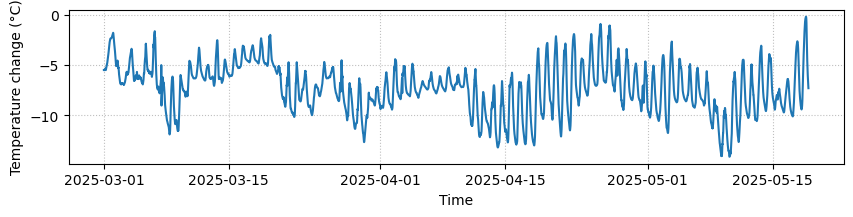

In [ ]:
T, _ = Strain2Temp(das_temp.strain.median(dim='channel').values)
print(min(T), max(T))
plt.figure(figsize=(10,2))
plt.xlabel('Time')
plt.ylabel('Temperature change (°C)')
plt.plot(das_temp.time, T)
plt.grid(ls=':', c='grey', alpha=0.5)
plt.show()

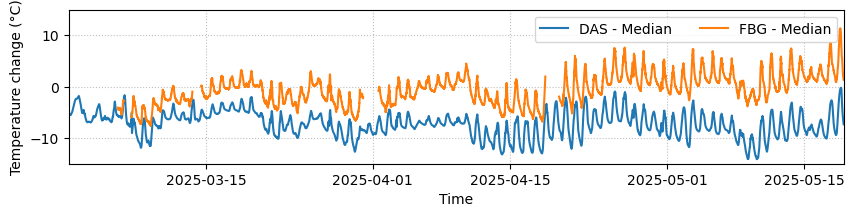

In [ ]:
plt.figure(figsize=(10,2))
plt.plot(das_temp.time, T, label='DAS - Median')
plt.plot(fbg_temp.Time, median_temp*1000/12, label='FBG - Median')
#plt.fill_between(das_temp.time, Strain2Temp(das_temp.strain.median(dim='channel').values- das_temp.strain.std(dim='channel').values),
                  #Strain2Temp(das_temp.strain.median(dim='channel').values+ das_temp.strain.std(dim='channel').values), label='DAS - 1 std', alpha=.3)
#plt.fill_between(fbg_temp.Time, std_temp*1000/12 + median_temp*1000/12, 
                 #median_temp*1000/12 - std_temp*1000/12, color='C1', alpha=.3, label='FBG - 1 std')
plt.xlabel('Time')
plt.xlim(das_temp.time.values[0], das_temp.time.values[-1])
plt.ylim(-15, 15)
plt.legend(ncols=2)
plt.grid(ls=':', c='grey', alpha=0.5)
plt.ylabel('Temperature change (°C)')
plt.show()
